In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
!pip install scikit-learn numpy pandas
!pip install scikit-learn
from sklearn.metrics import recall_score, precision_score, f1_score

In [ ]:
#importin Gita maternity data
df=pd.read_csv('/content/GITA MATERNITY.csv')


In [ ]:
df.shape

(1412, 94)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1412 entries, 0 to 1411
Data columns (total 94 columns):
 #   Column                                                                                                                           Non-Null Count  Dtype  
---  ------                                                                                                                           --------------  -----  
 0   start                                                                                                                            1412 non-null   object 
 1   end                                                                                                                              1412 non-null   object 
 2   start-geopoint                                                                                                                   1173 non-null   object 
 3   _start-geopoint_latitude                                                                          

In [ ]:
df.describe()

,_start-geopoint_latitude,_start-geopoint_longitude,_start-geopoint_altitude,_start-geopoint_precision,Sub County (Siaya),Facility Name (Nyando),Facility Name (Seme),Facility Name (Nyakach),Facility Name (Kisumu Central)/Kisumu County Referral Hospital - #13704,Facility Name (Kisumu West),...,Discharge baby 5,Village/estate. (Use the code 'MD' for Missing data or 'NIR' for Not in the register as a response to this question if needed.),Parity (Use the code 'MD' for Missing data or 'NIR' for Not in the register as a response to this question if needed.),Diagnosis (Detailed),Remarks,_id,_validation_status,_notes,_tags,_index
count,1173.000000,1173.000000,1173.000000,1173.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.412000e+03,0.0,0.0,0.0,1412.000000
mean,-0.028652,34.791582,42.136487,800.840868,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,4.658291e+08,NaN,NaN,NaN,23020.609773
std,0.000722,0.000832,221.504271,849.048065,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,5.070727e+06,NaN,NaN,NaN,5282.078046
min,-0.031487,34.790477,0.000000,20.093000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,4.565099e+08,NaN,NaN,NaN,9731.000000
25%,-0.029331,34.790822,0.000000,200.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,4.610864e+08,NaN,NaN,NaN,18386.750000
50%,-0.028619,34.791446,0.000000,200.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,4.649671e+08,NaN,NaN,NaN,22640.500000
75%,-0.027894,34.792203,0.000000,2000.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,4.710997e+08,NaN,NaN,NaN,28353.250000
max,-0.027175,34.796345,1206.599976,2000.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,4.752166e+08,NaN,NaN,NaN,31583.000000


In [ ]:
#shorten the name for the column containing number of babies born
df.rename(columns={'How many babies does the client have in the register you are looking at?':'born babies'}, inplace=True)

In [ ]:
#Retain only columns need  and get rid of the rest
df_select=df[['Admission  no.','ANC visits', 'born babies','Birth outcome 1','Birth weight 1','Birth outcome 2','Birth weight 2','Delivery mode','Mother status']]
print(df_select)

     Admission  no.  ANC visits  born babies Birth outcome 1  Birth weight 1  \
0              1234           4          2.0              LB             3.5   
1            22-Jan           5          1.0              LB          3900.0   
2            22-Feb           7          1.0              LB          3600.0   
3            22-Mar           2          1.0              LB          2600.0   
4            22-Apr           3          1.0              LB          3500.0   
...             ...         ...          ...             ...             ...   
1407            464           3          1.0              LB          2900.0   
1408            499           6          1.0              LB          3400.0   
1409            500           4          1.0              LB          2700.0   
1410            501           7          1.0              LB          3500.0   
1411            502           1          1.0              LB          3100.0   

     Birth outcome 2  Birth weight 2 De

In [ ]:
df_select.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1412 entries, 0 to 1411
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Admission  no.   1412 non-null   object 
 1   ANC visits       1412 non-null   int64  
 2   born babies      1321 non-null   float64
 3   Birth outcome 1  1314 non-null   object 
 4   Birth weight 1   1314 non-null   float64
 5   Birth outcome 2  9 non-null      object 
 6   Birth weight 2   9 non-null      float64
 7   Delivery mode    1321 non-null   object 
 8   Mother status    1321 non-null   object 
dtypes: float64(3), int64(1), object(5)
memory usage: 99.4+ KB


In [ ]:
#Check for mothers appearing multiple times due to admission no. appearing multiple times
number_multiple_mothers = (df_select['Admission  no.'].value_counts() > 1).sum()

print("Number of mothers with multiple records:",
      number_multiple_mothers)

Number of mothers with multiple records: 348


In [ ]:
#dropping the admission numbers that are duplicated but retaining the ones that appear first in the dataset

df_next= df_select.drop_duplicates(subset='Admission  no.', keep='first')

In [ ]:
print(df_next.columns.tolist())

['Admission  no.', 'ANC visits', 'born babies', 'Birth outcome 1', 'Birth weight 1', 'Birth outcome 2', 'Birth weight 2', 'Delivery mode', 'Mother status']


In [ ]:
print(df_next.columns.tolist())

['Admission  no.', 'ANC visits', 'born babies', 'Birth outcome 1', 'Birth weight 1', 'Birth outcome 2', 'Birth weight 2', 'Delivery mode', 'Mother status']


Since we have multiple columns of birth outcome and birth weight,i need to melt and merge them

In [ ]:

# Melt birth weight
weights = df_next.melt(
    id_vars=['Admission  no.', 'ANC visits'],
    value_vars=['Birth weight 1', 'Birth weight 2'],
    var_name='Baby',
    value_name='Birth Weight'
)

# Extract baby number
weights['Baby Number'] = weights['Baby'].str.extract(r'(\d+)$').astype(int)

# Melt birth outcome
outcomes =df_next.melt(
    id_vars=['Admission  no.'],
    value_vars=['Birth outcome 1', 'Birth outcome 2'],
    var_name='Baby',
    value_name='Birth Outcome'
)

# Extract baby number
outcomes['Baby Number'] = outcomes['Baby'].str.extract(r'(\d+)$').astype(int)

# Remove the original Baby column
weights = weights.drop(columns='Baby')
outcomes = outcomes.drop(columns='Baby')

# Combine weight and outcome
df_long = pd.merge(
    weights,
    outcomes,
    on=['Admission  no.', 'Baby Number'],
    how='left'
)

print(df_long)

     Admission  no.  ANC visits  Birth Weight  Baby Number Birth Outcome
0              1234           4           3.5            1            LB
1            22-Jan           5        3900.0            1            LB
2            22-Feb           7        3600.0            1            LB
3            22-Mar           2        2600.0            1            LB
4            22-Apr           3        3500.0            1            LB
...             ...         ...           ...          ...           ...
1897            461           6           NaN            2           NaN
1898            499           6           NaN            2           NaN
1899            500           4           NaN            2           NaN
1900            501           7           NaN            2           NaN
1901            502           1           NaN            2           NaN

[1902 rows x 5 columns]


In [ ]:
#remove rows with empty birth weights
df_long = df_long.dropna(subset=['Birth Weight'])

In [ ]:
#remove rows with empty birth outcomes
df_long = df_long.dropna(subset=['Birth Outcome'])

In [ ]:
print(df_long)

     Admission  no.  ANC visits  Birth Weight  Baby Number Birth Outcome
0              1234           4           3.5            1            LB
1            22-Jan           5        3900.0            1            LB
2            22-Feb           7        3600.0            1            LB
3            22-Mar           2        2600.0            1            LB
4            22-Apr           3        3500.0            1            LB
...             ...         ...           ...          ...           ...
1137         200/22           3        2100.0            2            LB
1216            274           1         800.0            2            LB
1327         407/22           2        1500.0            2            LB
1363         434/22           2        1500.0            2            LB
1591         299/23           4        2300.0            2            LB

[907 rows x 5 columns]


In [ ]:
#Now to remove outliers in baby weights
Q1 = df_long['Birth Weight'].quantile(0.25)
Q3 = df_long['Birth Weight'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR  #multiply by interquartile range to give us a reasonable distance beyond normal data spread
upper_limit = Q3 + 1.5 * IQR

df_long = df_long[
    (df_long['Birth Weight'] >= lower_limit) &
    (df_long['Birth Weight'] <= upper_limit)
]

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

Lower limit: 1900.0
Upper limit: 4300.0


In [ ]:
#number of babies left after removing outliers
print(len(df_long))

875


NUMERICALY ENCODING THE BIRTH OUTCOMES

In [ ]:
print(df_long['Birth Outcome'].unique())

['LB' 'MD' 'FSB' 'LN' 'LB ']


In [ ]:
print(df_long['Birth Outcome'].value_counts())

Birth Outcome
LB     868
FSB      3
MD       2
LN       1
LB       1
Name: count, dtype: int64


In [ ]:
df_long['Birth Outcome'] = df_long['Birth Outcome'].replace(
    'LB ', 'LB'
)

In [ ]:
#Final birth outcomes
print(df_long['Birth Outcome'].value_counts())

Birth Outcome
LB     869
FSB      3
MD       2
LN       1
Name: count, dtype: int64


In [ ]:
#get rid of MD and LN
df_long = df_long[
    ~df_long['Birth Outcome'].isin(['MD', 'LN'])
]

In [ ]:
#numerically encoding the birth outcomes of the babies
df_long['Birth Outcome_Encoded'] = df_long['Birth Outcome'].map({
    'LB': 1,
    'FSB': 0,

})

print(df_long)

     Admission  no.  ANC visits  Birth Weight  Baby Number Birth Outcome  \
1            22-Jan           5        3900.0            1            LB   
2            22-Feb           7        3600.0            1            LB   
3            22-Mar           2        2600.0            1            LB   
4            22-Apr           3        3500.0            1            LB   
5            22-May           3        3100.0            1            LB   
...             ...         ...           ...          ...           ...   
948             500           4        2700.0            1            LB   
949             501           7        3500.0            1            LB   
950             502           1        3100.0            1            LB   
1137         200/22           3        2100.0            2            LB   
1591         299/23           4        2300.0            2            LB   

      Birth Outcome_Encoded  
1                         1  
2                         1

In [ ]:
print(df_long['ANC visits'].value_counts())

ANC visits
5     182
4     179
6     136
3     117
7      79
2      70
8      44
1      38
9      13
98      7
0       4
10      3
Name: count, dtype: int64


In [ ]:
#Get rid of anc visits with 98 as values
df_long = df_long[
    ~df_long['ANC visits'].isin([98])
]

In [ ]:
print(df_long['ANC visits'].value_counts())

ANC visits
5     182
4     179
6     136
3     117
7      79
2      70
8      44
1      38
9      13
0       4
10      3
Name: count, dtype: int64


CORRELATION BETWEEN ANC VISITS AND BIRTH WEIGHTS

In [ ]:
correlation = df_long["ANC visits"].corr(df_long["Birth Weight"])
print(correlation)

0.08771178789993905


In [ ]:
from scipy.stats import pearsonr

In [ ]:
df_long["ANC visits"] = pd.to_numeric(
    df_long["ANC visits"], errors="coerce"
)
df_long["Birth Weight"] = pd.to_numeric(
    df_long["Birth Weight"], errors="coerce"
)


# Calculate Pearson correlation and p-value
r, p_value = pearsonr(
    df_long["ANC visits"],
    df_long["Birth Weight"]
)

print("Pearson correlation coefficient (r):", round(r, 3))
print("P-value:", round(p_value, 4))

# Interpret the result
if p_value < 0.05:
    print("The relationship is statistically significant.")
else:
    print("The relationship is not statistically significant.")


Pearson correlation coefficient (r): 0.088
P-value: 0.0099
The relationship is statistically significant.


VISUALS

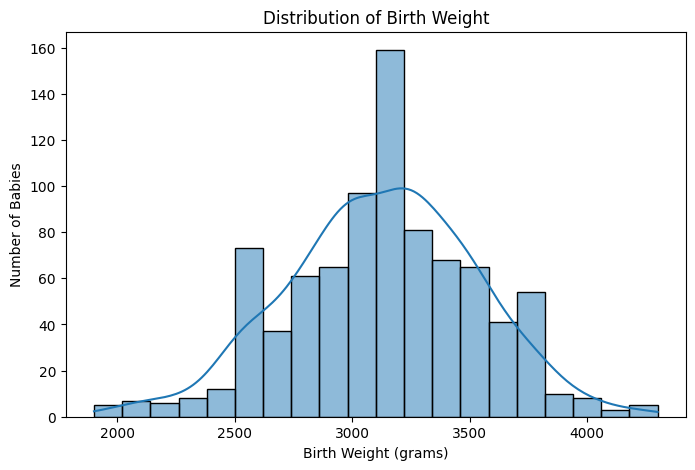

In [ ]:
#Histogram showing birth distribution of birth weight
plt.figure(figsize=(8,5))

sns.histplot(
    df_long['Birth Weight'],
    bins=20,
    kde=True
)

plt.xlabel('Birth Weight (grams)')
plt.ylabel('Number of Babies')
plt.title('Distribution of Birth Weight')

plt.show()

In [ ]:
#Scatterplot

import matplotlib.pyplot as plt
import seaborn as sns

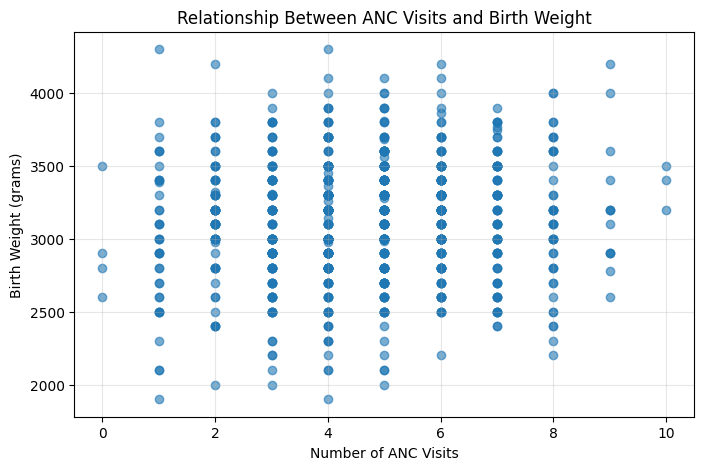

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(
    df_long["ANC visits"],
    df_long["Birth Weight"],
    alpha=0.6
)

plt.title("Relationship Between ANC Visits and Birth Weight")
plt.xlabel("Number of ANC Visits")
plt.ylabel("Birth Weight (grams)")
plt.grid(True, alpha=0.3)
plt.show()

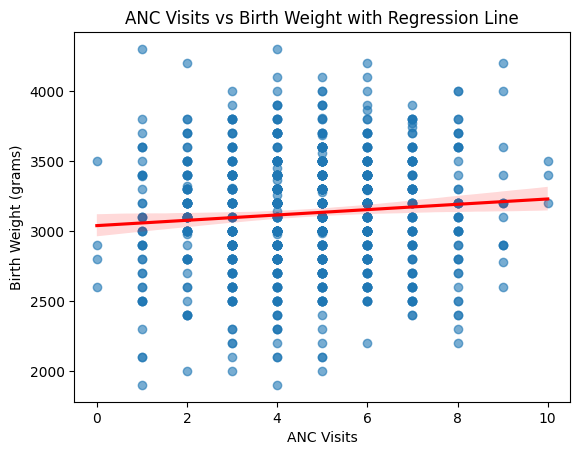

In [ ]:
#plotting a regression line to show effect of higher anc visits on birthweights
sns.regplot(
    data=df_long,
    x="ANC visits",
    y="Birth Weight",
    scatter_kws={"alpha": 0.6},
    line_kws={"color": "red"}
)

plt.title("ANC Visits vs Birth Weight with Regression Line")
plt.xlabel("ANC Visits")
plt.ylabel("Birth Weight (grams)")
plt.show()

the red line sloping upwards indicates higher weight associated with higher anc visits

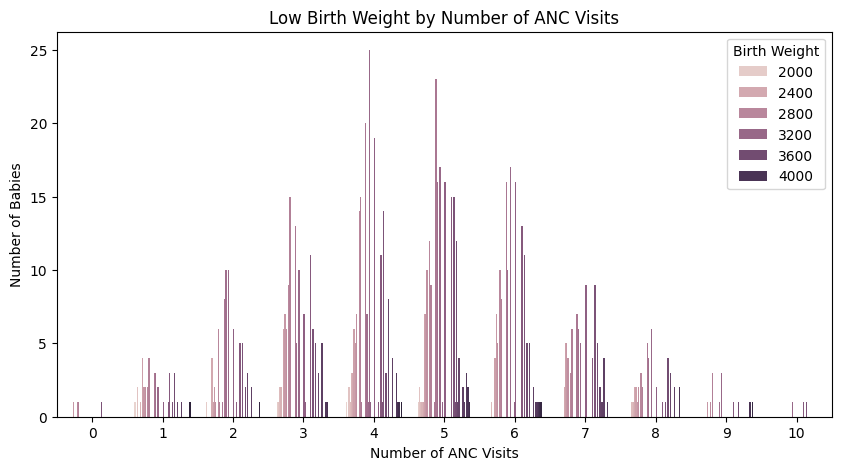

In [ ]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=df_long,
    x='ANC visits',
    hue='Birth Weight'
)

plt.xlabel('Number of ANC Visits')
plt.ylabel('Number of Babies')
plt.title('Low Birth Weight by Number of ANC Visits')

plt.show()

In [ ]:
print(df_long)

     Admission  no.  ANC visits  Birth Weight  Baby Number Birth Outcome  \
1            22-Jan           5        3900.0            1            LB   
2            22-Feb           7        3600.0            1            LB   
3            22-Mar           2        2600.0            1            LB   
4            22-Apr           3        3500.0            1            LB   
5            22-May           3        3100.0            1            LB   
...             ...         ...           ...          ...           ...   
948             500           4        2700.0            1            LB   
949             501           7        3500.0            1            LB   
950             502           1        3100.0            1            LB   
1137         200/22           3        2100.0            2            LB   
1591         299/23           4        2300.0            2            LB   

      Birth Outcome_Encoded  
1                         1  
2                         1

CLASSIFICATION OF BIRTH WEIGHTS

In [ ]:
#First,classification on birth weights to low and normal

df_long['Low_Birth_Weight'] = (
    df_long['Birth Weight'] < 2500
).astype(int)

In [ ]:
#number of normal and low birth weights with 1 representing low birth weight
print(df_long['Low_Birth_Weight'].value_counts())

Low_Birth_Weight
0    827
1     38
Name: count, dtype: int64


In [ ]:
#percentage of normal and low birth weights
print(
    df_long['Low_Birth_Weight']
    .value_counts(normalize=True) * 100
)

Low_Birth_Weight
0    95.606936
1     4.393064
Name: proportion, dtype: float64


In [ ]:
from sklearn.model_selection import train_test_split

LINEAR REGRESSION

In [ ]:
#selecting input and output
X = df_long[["ANC visits"]]
y = df_long["Birth Weight"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Creating the Linear Regression model
model = LinearRegression()

# Training the model
model.fit(X_train, y_train)

# Predicting birth weight
y_pred = model.predict(X_test)


In [ ]:
# Evaluating the model
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))
print("Root Mean Squared Error:",
      np.sqrt(mean_squared_error(y_test, y_pred)))
print("R-squared:", r2_score(y_test, y_pred))

Mean Absolute Error: 326.43431135259635
Root Mean Squared Error: 403.02417134649
R-squared: -0.01896751397668739


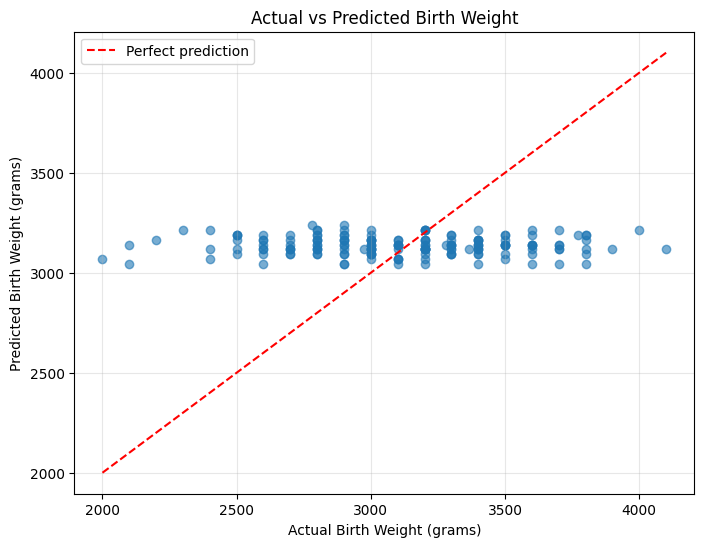

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

#prediction reference line
min_weight = min(y_test.min(), y_pred.min())
max_weight = max(y_test.max(), y_pred.max())

plt.plot(
    [min_weight, max_weight],
    [min_weight, max_weight],
    linestyle="--",
    color="red",
    label="Perfect prediction"
)

plt.xlabel("Actual Birth Weight (grams)")
plt.ylabel("Predicted Birth Weight (grams)")
plt.title("Actual vs Predicted Birth Weight")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
errors = y_pred - y_test

print("Mean prediction error:",
      round(errors.mean(), 2), "grams")

Mean prediction error: 27.97 grams


OPTIMIZATION OF THE LINEAR REGRESSION MODEL

In [ ]:
#Pipeline creation
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge())
])

#Testing different Ridge regularisation strengths
parameters = {
    "model__alpha": [0.01, 0.1, 1, 10, 100]
}

search = GridSearchCV(
    pipeline,
    parameters,
    cv=5,
    scoring="neg_mean_absolute_error"
)

#Training and selecting the best setting using cross-validation
search.fit(X_train, y_train)

best_model = search.best_estimator_

# Making predictions on the test data
y_pred = best_model.predict(X_test)

#Evaluating the model
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Best parameters:", search.best_params_)
print("Best cross-validation MAE:", round(-search.best_score_, 2), "grams")
print("Test MAE:", round(mae, 2), "grams")
print("Test RMSE:", round(rmse, 2), "grams")
print("Test R²:", round(r2, 3))

Best parameters: {'model__alpha': 100}
Best cross-validation MAE: 323.47 grams
Test MAE: 325.53 grams
Test RMSE: 402.34 grams
Test R²: -0.016


LOGISTIC REGRESSION

In [ ]:
X = df_long[['ANC visits']]
y = df_long['Low_Birth_Weight']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression()

log_model.fit(X_train, y_train)

y_pred = log_model.predict(X_test)

#Make prediction

print(y_pred)


[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [ ]:
from sklearn.metrics import accuracy_score

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 3))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 3))

Accuracy: 0.954
Precision: 0.0
Recall: 0.0
F1-score: 0.0


In [ ]:
#Accuracy evaluation
#95.38% accurate

from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.953757225433526


DECISION TREE REGRESSION

In [ ]:
from sklearn.tree import DecisionTreeRegressor


In [ ]:
# Preparing the data
model_df = df_long[["ANC visits", "Birth Weight"]].copy()

model_df["ANC visits"] = pd.to_numeric(
    model_df["ANC visits"], errors="coerce"
)
model_df["Birth Weight"] = pd.to_numeric(
    model_df["Birth Weight"], errors="coerce"
)

model_df = model_df.dropna()

In [ ]:
# input and output
X = model_df[["ANC visits"]]
y = model_df["Birth Weight"]

#  Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [ ]:
# Creation and training the model
model = DecisionTreeRegressor(
    max_depth=4,
    random_state=42
)

model.fit(X_train, y_train)

# Predict birth weights
y_pred = model.predict(X_test)

In [ ]:
#Evaluation of the model
print("MAE:", mean_absolute_error(y_test, y_pred), "grams")
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R-squared:", r2_score(y_test, y_pred))


MAE: 332.11877054755956 grams
RMSE: 410.24680273144946
R-squared: -0.055816782738135284


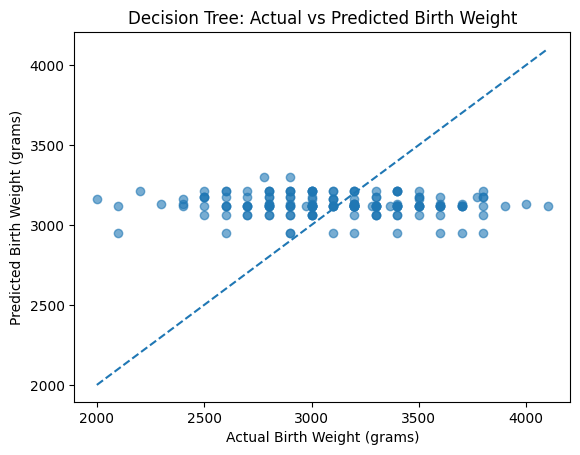

In [ ]:
#Plotting actual vs predicted values
plt.scatter(y_test, y_pred, alpha=0.6)

lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())

plt.plot(
    [lower, upper], [lower, upper],
    linestyle="--"
)

plt.xlabel("Actual Birth Weight (grams)")
plt.ylabel("Predicted Birth Weight (grams)")
plt.title("Decision Tree: Actual vs Predicted Birth Weight")
plt.show()

In [ ]:
dt = DecisionTreeRegressor(random_state=42)

# Parameters to test
dt_parameters = {
    "max_depth": [3, 5, 7, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5, 10]
}

# Optimise the model using cross-validation
dt_search = GridSearchCV(
    estimator=dt,
    param_grid=dt_parameters,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

dt_search.fit(X_train, y_train)

# Get the best model
best_dt = dt_search.best_estimator_

# Make predictions
dt_pred = best_dt.predict(X_test)

# Evaluate the model
print("Best parameters:", dt_search.best_params_)
print("Best cross-validation MAE:",
      round(-dt_search.best_score_, 2), "grams")
print("Test MAE:",
      round(mean_absolute_error(y_test, dt_pred), 2), "grams")
print("Test RMSE:",
      round(np.sqrt(mean_squared_error(y_test, dt_pred)), 2), "grams")
print("Test R²:", round(r2_score(y_test, dt_pred), 3))

Best parameters: {'max_depth': 5, 'min_samples_leaf': 5, 'min_samples_split': 2}
Best cross-validation MAE: 324.04 grams
Test MAE: 332.21 grams
Test RMSE: 410.35 grams
Test R²: -0.056


USING RANDOM FOREST

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

In [ ]:
model_df = df_long[["ANC visits", "Birth Weight"]].copy()

X = model_df[["ANC visits"]]
y = model_df["Birth Weight"]

#splitiing the data into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

#model creation
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

#model training
rf_model.fit(X_train, y_train)

#Birth weights prediction
y_pred = rf_model.predict(X_test)

In [ ]:
#mean absolute error evaluation
mae = mean_absolute_error(y_test, y_pred)

print("Mean Absolute Error:", round(mae, 2), "grams")

Mean Absolute Error: 332.02 grams


In [ ]:
#root mean squared evaluation
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print("Root Mean Squared Error:", round(rmse, 2), "grams")

Root Mean Squared Error: 410.03 grams


In [ ]:
#R-squared
r2 = r2_score(y_test, y_pred)
print("R-squared:", round(r2, 3))

R-squared: -0.055


In [ ]:
#Creating the Random Forest model
rf = RandomForestRegressor(random_state=42)

#Parameters tested
rf_parameters = {
    "n_estimators": [100, 200],
    "max_depth": [5, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5]
}

#Optimising using cross-validation
rf_search = GridSearchCV(
    estimator=rf,
    param_grid=rf_parameters,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

rf_search.fit(X_train, y_train)

#Get the best model
best_rf = rf_search.best_estimator_

#Making predictions
rf_pred = best_rf.predict(X_test)

#Evaluating the model
print("Best parameters:", rf_search.best_params_)
print("Best cross-validation MAE:",
      round(-rf_search.best_score_, 2), "grams")
print("Test MAE:",
      round(mean_absolute_error(y_test, rf_pred), 2), "grams")
print("Test RMSE:",
      round(np.sqrt(mean_squared_error(y_test, rf_pred)), 2), "grams")
print("Test R²:", round(r2_score(y_test, rf_pred), 3))

Best parameters: {'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 2, 'n_estimators': 100}
Best cross-validation MAE: 323.87 grams
Test MAE: 332.4 grams
Test RMSE: 410.46 grams
Test R²: -0.057


XGBoost


In [ ]:
!pip install xgboost

In [ ]:
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
#introduction of the input and output
X = df_long[["ANC visits"]]
y = df_long["Birth Weight"]

In [ ]:
# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Creation and training of the model
model = XGBRegressor(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.05,
    objective="reg:squarederror",
    random_state=42
)

model.fit(X_train, y_train)

# Predict birth weight
predictions = model.predict(X_test)


In [ ]:
# model evaluation

print("MAE:", mean_absolute_error(y_test, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
print("R²:", r2_score(y_test, predictions))

MAE: 331.7853961569725
RMSE: 409.87806482542743
R²: -0.05391965787122355


In [ ]:
df_long.to_csv("processed_Gita_maternity.csv", index=False)

# Download the saved file to your computer
from google.colab import files
files.download("processed_Gita_maternity.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>